# Klassifikation

## Präambel

Wir laden alle Pakete und Module, die wir im Folgenden benötigen.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn import tree
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions

import torch

## Daten

Der Iris-Datensatz ist ein beliebter Beispieldatensatz. Er enthält vier Merkmale:

* Länge der Kelchblätter (Sepalen, engl. sepal)
* Breite der Kelchblätter
* Länge der Kronblätter (Petalen, engl. petal)
* Breite der Kronblätter

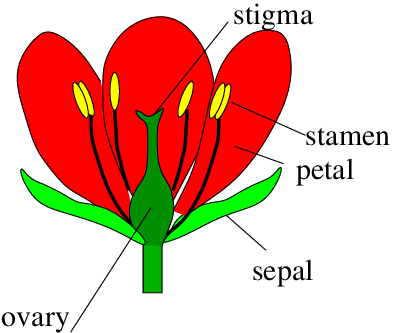

In [2]:
# Lade die Iris-Daten
iris = load_iris()

# Speichere den Input-Datensatz unter X
X = iris.data
# und die Klasse unter y
y = iris.target

### Ein Blick auf die Daten

In [3]:
# Namen der vier Merkmale
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

Die vier Merkmale sind Länge und Breite der Kelch- und Kronblätter, jeweils in Zentimetern.

In [4]:
# Zeige X
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

`X` ist eine Matrix mit 150 Zeilen (Blüten) und 4 Spalten (Merkmale in der Reihenfolge von `iris.feature_names`). Die erste Blüte hat z. B. 5,1 cm lange und 3,5 cm breite Kelchblätter sowie 1,4 cm lange und 0,2 cm breite Kronblätter.

In [5]:
# Wir beschränken uns auf die 1. und 3. Spalte des Datensatzes
X = X[:,[0, 2]]

Damit wir die Ergebnisse in einer zweidimensionalen Grafik darstellen können, verwenden wir nur zwei Merkmale: die Länge der Kelchblätter (Spalte 0) und die Länge der Kronblätter (Spalte 2). Python zählt die Spalten ab 0.

In [6]:
# Namen der drei Klassen (Iris-Arten)
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

Der Datensatz enthält drei Iris-Arten. Sie sind in `y` als Zahlen kodiert: 0 = *setosa*, 1 = *versicolor*, 2 = *virginica*.

In [7]:
# Zeige y
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

`y` enthält für jede der 150 Blüten die Klasse. Die Daten sind nach Klassen sortiert, und jede Art kommt genau 50-mal vor. Der Datensatz ist also *balanciert*.

### Grafische Darstellung

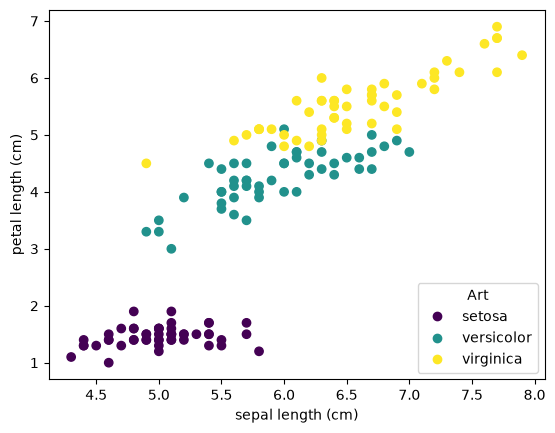

In [8]:
# Generiere eine leere Grafik
fig, ax = plt.subplots()

# Erstelle den Scatterplot
scatter = ax.scatter(x = X[:, 0],
                     y = X[:, 1],
                     c = y)

# Benenne die Achsen
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[2])

# Füge eine Legende hinzu
ax.legend(scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Art")

*Setosa* (unten links) unterscheidet sich klar von den anderen beiden Arten: Ihre Kronblätter sind deutlich kürzer. *Versicolor* und *virginica* überlappen sich dagegen teilweise. Bei diesen beiden Arten werden die Modelle daher am ehesten Fehler machen.

Die Zeile `<matplotlib.legend.Legend …>` über der Grafik ist nur eine Beschreibung des Legenden-Objekts.

Für jedes Modell zeichnen wir die *Entscheidungsregionen*: Die Farbe zeigt für jeden Punkt der Ebene, welche Art das Modell dort vorhersagen würde. Damit wir den Code nicht jedes Mal wiederholen müssen, schreiben wir dafür eine eigene Funktion. Sie verwendet `plot_decision_regions` aus dem Paket `mlxtend` und ergänzt die Achsenbeschriftungen und die Namen der Arten.

In [9]:
# Zeichne die Entscheidungsregionen eines Modells mit den Datenpunkten
def plot_regions(clf, X, y, class_names = iris.target_names):
    ax = plot_decision_regions(X = X, y = y, clf = clf, legend = 2)
    ax.set(xlabel = iris.feature_names[0], ylabel = iris.feature_names[2])
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles, class_names, title = "Art") # Namen statt Nummern in der Legende
    plt.show()

## Entscheidungsbaum (Decision Tree)

In [10]:
# Generiere ein "leeres" Modell
dcsntree = tree.DecisionTreeClassifier(random_state=0)

In [11]:
# Zeige Ergebnis an
dcsntree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

Vor dem Training zeigt Jupyter nur die Einstellungen des Modells an. `random_state=0` sorgt dafür, dass das Ergebnis reproduzierbar ist.

In [12]:
# Trainiere das Modell mit den Daten
dcsntree.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [13]:
# Zeige Ergebnis an
dcsntree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

Die Ausgabe sieht genauso aus wie vor dem Training. Das trainierte Modell speichert die gelernten Regeln intern, sie werden in dieser Kurzdarstellung aber nicht angezeigt.

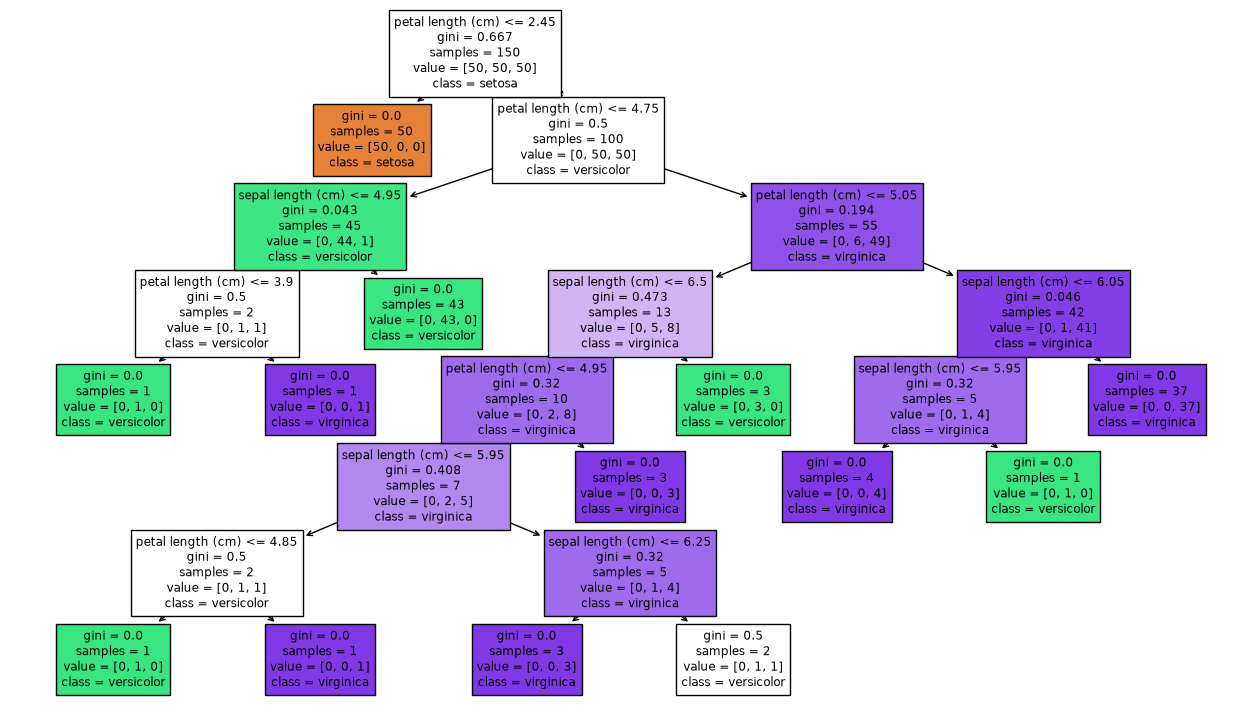

In [14]:
# Zeige den Entscheidungsbaum mit den Namen der Merkmale und Arten
plt.figure(figsize = (16, 9))
tree.plot_tree(dcsntree, feature_names = [iris.feature_names[0], iris.feature_names[2]],
               class_names = list(iris.target_names), filled = True)
plt.show()

Jeder Kasten ist ein Knoten des Baums. Die erste Zeile enthält die Entscheidungsregel. Ist sie erfüllt, geht es nach links, sonst nach rechts. `gini` ist die Unreinheit (0 = alle Blüten gehören zur selben Klasse), `samples` die Anzahl der Blüten im Knoten, `value` ihre Verteilung auf die drei Klassen und `class` die häufigste Klasse. Die Farbe zeigt diese Klasse, je kräftiger, desto reiner der Knoten.

Schon die erste Regel (Kronblattlänge ≤ 2,45 cm) trennt alle 50 *setosa*-Blüten ab. Die weiteren Ebenen unterscheiden *versicolor* und *virginica*. Weil der Baum ohne Begrenzung wächst, bildet er auch Knoten mit nur einer einzigen Blüte. Das ist ein Hinweis auf *Overfitting*: Der Baum lernt einzelne Ausnahmen auswendig.

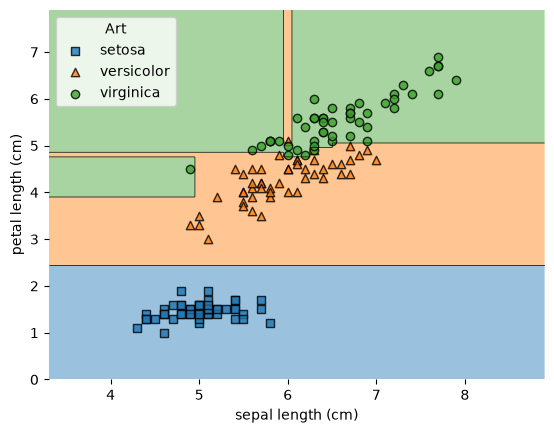

In [15]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(dcsntree, X, y)

Die farbigen Flächen zeigen, welche Klasse das Modell für jeden Punkt der Ebene vorhersagt. Die Grenzen des Entscheidungsbaums verlaufen immer parallel zu den Achsen, weil jede Regel nur ein Merkmal betrifft. Die kleinen Rechtecke und schmalen Streifen entstehen durch Regeln für einzelne Blüten, ein weiteres Zeichen für Overfitting.

In [16]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, dcsntree.predict(X))
cm

array([[50,  0,  0],
       [ 0, 50,  0],
       [ 0,  1, 49]])

Die Konfusionsmatrix vergleicht die tatsächlichen Klassen (Zeilen) mit den vorhergesagten Klassen (Spalten). Auf der Diagonale stehen die richtigen Vorhersagen. Der Baum klassifiziert 149 von 150 Blüten richtig, nur eine *virginica* wird als *versicolor* vorhergesagt. (Warum dieser eine Fehler unvermeidlich ist, erklären wir beim nächsten Modell.)

**Achtung:** Wir bewerten das Modell hier mit denselben Daten, mit denen es trainiert wurde. Das überschätzt die Güte des Modells, besonders bei Modellen, die zu Overfitting neigen. In der Praxis teilt man die Daten in Trainings- und Testdaten auf. Das machen wir im Abschnitt *Vergleich auf Testdaten*.

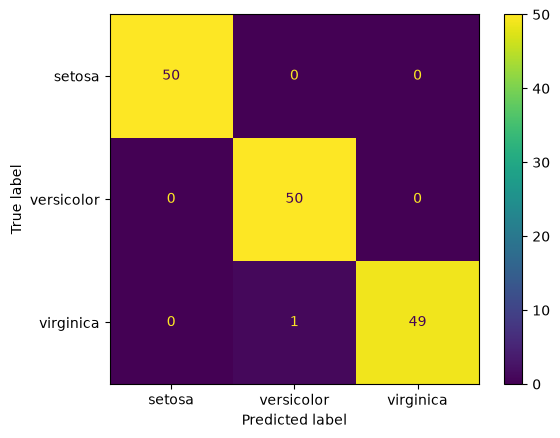

In [17]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

Dieselbe Matrix als Grafik: Je heller das Feld, desto mehr Blüten.

## k-nächste Nachbarn (KNN)

In [18]:
# Generiere ein "leeres" Modell
knn = KNeighborsClassifier(n_neighbors=1)

# Trainiere das Modell mit den Daten
knn = knn.fit(X, y)

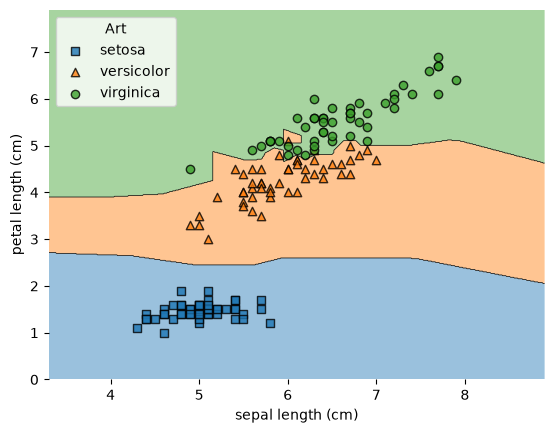

In [19]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(knn, X, y)

KNN ist ein *Lazy Learner*: Beim Training speichert es nur die Daten, gerechnet wird erst bei der Vorhersage. Eine neue Blüte erhält die Art, die unter ihren nächsten Nachbarn am häufigsten ist. Standardmäßig entscheiden die 5 nächsten Nachbarn (`n_neighbors=5`), wir verwenden hier nur einen.

Mit `n_neighbors=1` übernimmt jeder Punkt der Ebene die Klasse der nächstgelegenen Blüte aus den Trainingsdaten. Die Grenzen sind deshalb unregelmäßig und folgen einzelnen Datenpunkten.

In [20]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, knn.predict(X))
cm

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  0, 50]])

Auch KNN klassifiziert 149 von 150 Blüten richtig, hier wird eine *versicolor* als *virginica* vorhergesagt. Dass das Ergebnis auf den Trainingsdaten nicht perfekt ist, liegt an zwei Blüten mit genau denselben Werten (Kelchblatt 6,3 cm, Kronblatt 4,9 cm), von denen eine *versicolor* und eine *virginica* ist. Kein Modell kann beide richtig klassifizieren, mit diesen zwei Merkmalen sind also höchstens 149 von 150 möglich. Auf neuen Daten schneidet ein KNN mit nur einem Nachbarn deutlich schlechter ab, wie der Abschnitt *Vergleich auf Testdaten* zeigt.

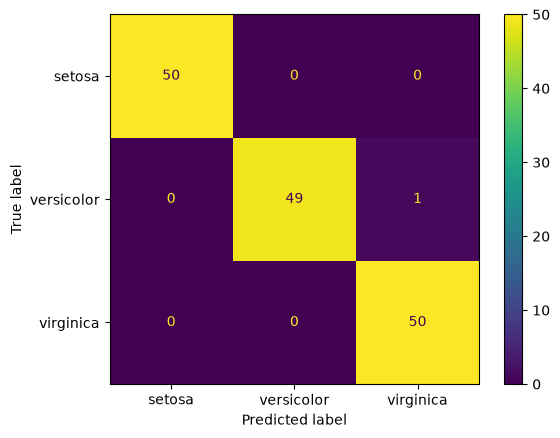

In [21]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

## Logistische Regression

In [22]:
# Generiere ein "leeres" Modell
logreg_res = LogisticRegression(random_state=0)

# Trainiere das Modell mit den Daten
logreg_res = logreg_res.fit(X, y)

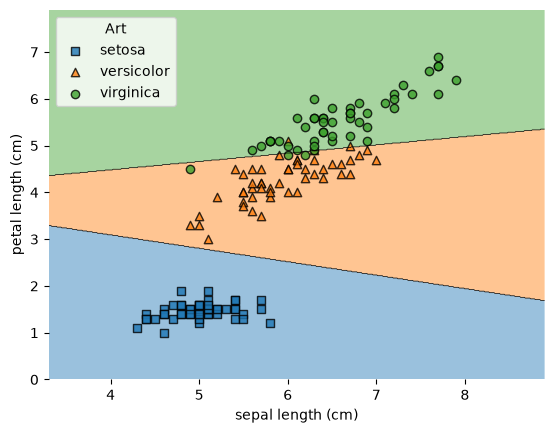

In [23]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(logreg_res, X, y)

Die logistische Regression ist ein *linearer Klassifikator*: Sie trennt die Klassen mit geraden Linien. Dadurch sind die Grenzen einfach und glatt, aber im Überlappungsbereich von *versicolor* und *virginica* liegen einige Punkte auf der falschen Seite.

In [24]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, logreg_res.predict(X))
cm

array([[50,  0,  0],
       [ 0, 47,  3],
       [ 0,  3, 47]])

144 von 150 Blüten werden richtig klassifiziert (96 %). Je drei *versicolor*- und *virginica*-Blüten werden verwechselt. Das einfachere Modell passt sich weniger an einzelne Punkte an und macht auf den Trainingsdaten daher mehr Fehler, ist aber weniger anfällig für Overfitting.

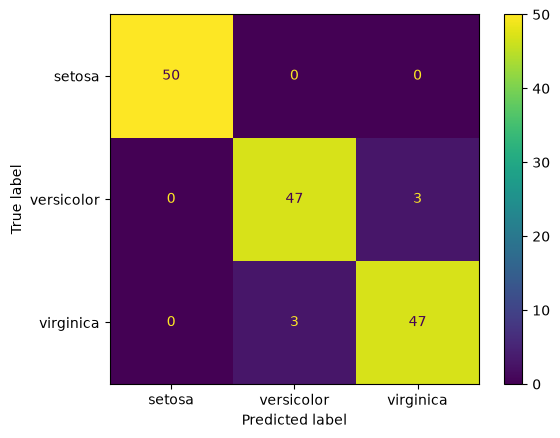

In [25]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

## Support-Vector-Machine (SVM)

In [26]:
# Generiere ein "leeres" Modell
svm_res = SVC(random_state=0)

# Trainiere das Modell mit den Daten
svm_res = svm_res.fit(X, y)

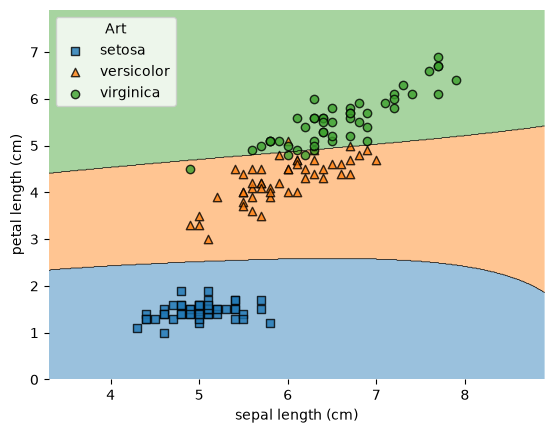

In [27]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(svm_res, X, y)

Die SVM (hier mit dem Standard-Kernel RBF) erzeugt geschwungene Grenzen. Sie sind flexibler als bei der logistischen Regression, aber glatter als beim Entscheidungsbaum oder bei KNN.

In [28]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, svm_res.predict(X))
cm

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0,  4, 46]])

144 von 150 Blüten werden richtig klassifiziert. Zwei *versicolor*-Blüten werden als *virginica* und vier *virginica*-Blüten als *versicolor* vorhergesagt.

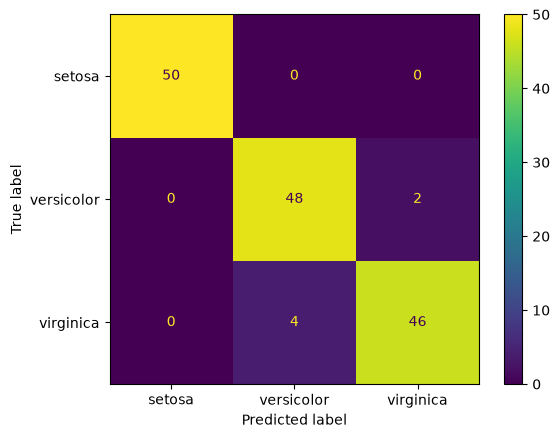

In [29]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

## Ensembles

Ein *Ensemble* kombiniert die Vorhersagen mehrerer Modelle. Jedes Modell macht andere Fehler. Werden die Vorhersagen gemittelt oder per Abstimmung zusammengeführt, gleichen sich diese Fehler teilweise aus, und das Ergebnis ist oft stabiler als jedes Einzelmodell.

### Random Forest

Ein Random Forest ist eine Sammlung vieler Entscheidungsbäume.

In [30]:
# Generiere ein "leeres" Modell
randfor_res = RandomForestClassifier(random_state=0)

# Trainiere das Modell mit den Daten
randfor_res = randfor_res.fit(X, y)

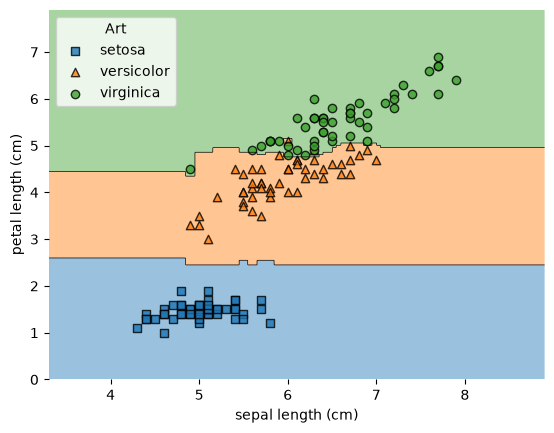

In [31]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(randfor_res, X, y)

Der Random Forest kombiniert 100 Entscheidungsbäume. Jeder Baum wird mit einer zufälligen Stichprobe der Blüten trainiert (mit Zurücklegen), und bei jeder Regel steht nur ein zufällig ausgewählter Teil der Merkmale zur Wahl, bei uns eines der beiden. Die Vorhersage ist die Mehrheit der Bäume. Die Grenzen verlaufen deshalb wie beim einzelnen Baum stufenförmig, sind aber weniger zerklüftet.

In [32]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, randfor_res.predict(X))
cm

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  0, 50]])

149 von 150 Blüten werden richtig klassifiziert, eine *versicolor* wird als *virginica* vorhergesagt.

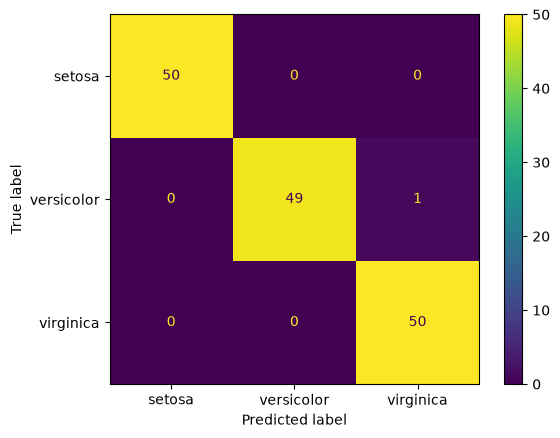

In [33]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

### Kombination verschiedener Modelle (Voting)

Es können auch unterschiedliche Arten von Modellen kombiniert werden. Im folgenden Beispiel werden die logistische Regression, der Random Forest und die SVM zusammengeführt. Bei `voting='soft'` mittelt das Ensemble die vorhergesagten Wahrscheinlichkeiten der drei Modelle, hier gewichtet im Verhältnis 2 : 1 : 1. Vorhergesagt wird die Art mit der höchsten mittleren Wahrscheinlichkeit.

In [34]:
# Generiere die "leeren" Modelle, die im Ensemble verwendet werden sollen
clf1 = LogisticRegression(random_state=0)
clf2 = RandomForestClassifier(random_state=0)
clf3 = SVC(random_state=0, probability=True) # probability=True: nötig für voting='soft'

# Füge die Modelle zusammen und gewichte sie
ensemble_res = EnsembleVoteClassifier(clfs=[clf1, clf2, clf3],
                              weights=[2, 1, 1],
                              voting='soft')

# Trainiere das Ensemble mit den Daten
ensemble_res = ensemble_res.fit(X, y)

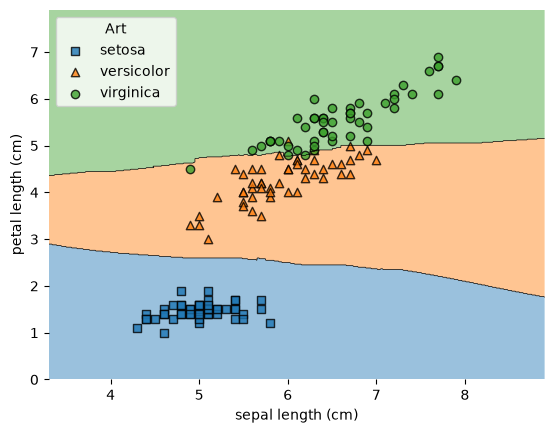

In [35]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(ensemble_res, X, y)

Die Grenzen des Ensembles sind eine Mischung aus den Grenzen der drei Modelle. Da die logistische Regression doppelt gewichtet ist, verlaufen sie fast wie bei der logistischen Regression, sind aber leicht gekrümmt (SVM) und haben kleine Stufen (Random Forest).

In [36]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, ensemble_res.predict(X))
cm

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0,  1, 49]])

147 von 150 Blüten werden richtig klassifiziert. Das Ensemble ist damit besser als die logistische Regression und die SVM allein, aber etwas schlechter als der Random Forest. Auf den Trainingsdaten gewinnt meist das flexibelste Modell. Ob das Ensemble auf neuen Daten besser ist, lässt sich nur mit Testdaten beurteilen (siehe nächster Abschnitt).

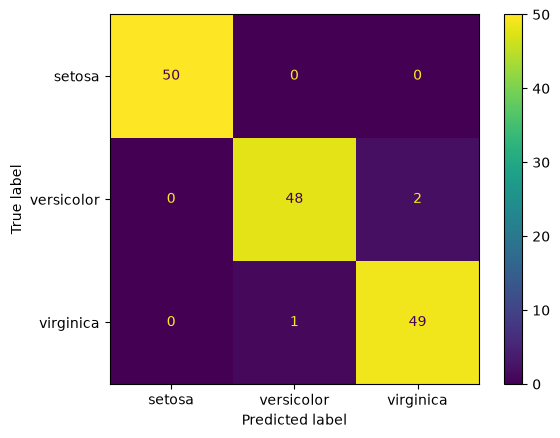

In [37]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

## Vergleich auf Testdaten

Bisher haben wir alle Modelle mit denselben Daten bewertet, mit denen sie trainiert wurden. Flexible Modelle wie der Entscheidungsbaum oder KNN mit einem Nachbarn können sich die Trainingsdaten aber fast auswendig merken (*Overfitting*). Entscheidend ist, wie gut ein Modell *neue* Blüten klassifiziert.

Wir teilen die Daten deshalb in Trainingsdaten (70 %) und Testdaten (30 %). Die Modelle lernen nur mit den Trainingsdaten und werden mit den Testdaten bewertet, die sie nie gesehen haben. `stratify=y` sorgt dafür, dass alle drei Arten in beiden Teilen gleich häufig vorkommen.

In [38]:
# Teile die Daten in Trainingsdaten (70 %) und Testdaten (30 %)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, stratify = y, random_state = 0)

# Die Modelle von oben, jeweils als neues 'leeres' Modell
models = {
    'Entscheidungsbaum': tree.DecisionTreeClassifier(random_state = 0),
    'KNN (1 Nachbar)': KNeighborsClassifier(n_neighbors = 1),
    'KNN (5 Nachbarn)': KNeighborsClassifier(n_neighbors = 5),
    'Logistische Regression': LogisticRegression(random_state = 0),
    'SVM': SVC(random_state = 0),
    'Random Forest': RandomForestClassifier(random_state = 0),
    'Ensemble': EnsembleVoteClassifier(clfs = [LogisticRegression(random_state = 0),
                                               RandomForestClassifier(random_state = 0),
                                               SVC(random_state = 0, probability = True)],
                                       weights = [2, 1, 1], voting = 'soft'),
}

# Trainiere jedes Modell mit den Trainingsdaten und bewerte es mit beiden Teilen
# score() gibt den Anteil der richtig klassifizierten Blüten an
results = []
for name, clf in models.items():
    clf.fit(X_train, y_train)
    results.append({'Modell': name,
                    'Trainingsdaten': clf.score(X_train, y_train),
                    'Testdaten': clf.score(X_test, y_test)})

results = pd.DataFrame(results).set_index('Modell')
results.round(3)

,Trainingsdaten,Testdaten
Modell,,
Entscheidungsbaum,1.000,0.956
KNN (1 Nachbar),1.000,0.956
KNN (5 Nachbarn),0.943,1.000
Logistische Regression,0.952,0.978
SVM,0.943,0.956
Random Forest,1.000,0.956
Ensemble,0.962,0.978


Auf den Trainingsdaten erreichen der Entscheidungsbaum, KNN mit einem Nachbarn und der Random Forest 100 %. Auf den Testdaten liegen alle drei nur bei 95,6 %, das sind zwei Fehler bei 45 Blüten. Die logistische Regression und das Ensemble klassifizieren die Testdaten besser (97,8 %), und KNN mit 5 Nachbarn erkennt sogar alle 45 Testblüten richtig. Die flexibelsten Modelle passen sich den Trainingsdaten am stärksten an und verlieren auf neuen Daten am meisten.

Mit nur 45 Testblüten verändert schon eine einzige Blüte den Anteil um 2,2 Prozentpunkte. Stabiler ist die **Kreuzvalidierung**: Die Daten werden in 10 Teile zerlegt. Jedes Modell wird 10-mal trainiert, jeweils mit 9 Teilen, und mit dem übrigen Teil getestet. So wird jede Blüte genau einmal als Testdaten verwendet. Der Mittelwert der 10 Ergebnisse ist das Maß für die Güte.

In [39]:
# 10 Teile, jeweils mit gleichen Anteilen der Arten (stratifiziert), zufällig gemischt
cv = StratifiedKFold(n_splits = 10, shuffle = True, random_state = 0)

# Mittlerer Anteil richtig klassifizierter Blüten über die 10 Durchgänge
results['Kreuzvalidierung'] = [cross_val_score(clf, X, y, cv = cv).mean() for clf in models.values()]
results.round(3)

,Trainingsdaten,Testdaten,Kreuzvalidierung
Modell,,,
Entscheidungsbaum,1.000,0.956,0.927
KNN (1 Nachbar),1.000,0.956,0.907
KNN (5 Nachbarn),0.943,1.000,0.940
Logistische Regression,0.952,0.978,0.947
SVM,0.943,0.956,0.927
Random Forest,1.000,0.956,0.940
Ensemble,0.962,0.978,0.940


In der Kreuzvalidierung liegt die logistische Regression mit 94,7 % vorne, knapp vor KNN mit 5 Nachbarn, dem Random Forest und dem Ensemble (je 94,0 %). KNN mit nur einem Nachbarn ist mit 90,7 % das schwächste Modell, obwohl es auf den Trainingsdaten perfekt war (100 %). Auf neuen Daten ergibt sich also eine ganz andere Reihenfolge als auf den Trainingsdaten. Die Unterschiede zwischen den besten Modellen sind allerdings klein: Ein Prozentpunkt entspricht hier 1,5 Blüten.

## Neuronale Netze

Zum Schluss trainieren wir ein einfaches neuronales Netz mit `PyTorch`. Wir gehen in zwei Schritten vor:

1. Zuerst unterscheidet das Netz nur zwei Arten, *setosa* und *virginica*. Dafür bekommt es zwei Output-Knoten, einen pro Art.
2. Danach erweitern wir es auf alle drei Arten. Dafür brauchen wir nur einen dritten Output-Knoten, der Rest des Codes bleibt gleich.

Jeder Output-Knoten berechnet einen Score dafür, dass eine Blüte zu seiner Art gehört. Die Art mit dem höchsten Score ist die Vorhersage.

In [40]:
# Speichere den Maximalwert jeder Spalte
X_max = X.max(axis=0)

# Normalisiere die Input-Daten: Teile jede Spalte durch ihren Maximalwert
def scale(inputs):
    return (inputs / X_max).astype(np.float32) # PyTorch rechnet standardmäßig mit 32-Bit-Gleitkommazahlen

Neuronale Netze lernen besser, wenn die Merkmale auf einer ähnlichen Skala liegen. Die Funktion `scale` teilt jede Spalte durch ihren Maximalwert, sodass beide Merkmale zwischen 0 und 1 liegen. `X` selbst bleibt in Zentimetern. Wir skalieren die Daten erst, wenn sie ins Netz gehen. So haben die Grafiken unten dieselben Achsen wie die Grafiken der anderen Modelle.

### Schritt 1: Zwei Klassen, zwei Output-Knoten

In [41]:
# Beschränke die Daten auf setosa (Label 0) und virginica (Label 2)
pos = y != 1
X_2 = X[pos]
y_2 = y[pos].copy() # copy(), damit y selbst unverändert bleibt

# Kodiere virginica neu: aus Label 2 wird 1, damit die Klassen 0 und 1 sind
y_2[y_2 == 2] = 1

Für den ersten Schritt verwenden wir nur *setosa* und *virginica*. Jedes Label gibt an, welcher Output-Knoten der richtige ist. Bei zwei Knoten müssen die Labels deshalb 0 und 1 sein, und wir kodieren *virginica* von 2 in 1 um.

In [42]:
# Spezifiziere die Anzahl der Input- und Output-Knoten
input_dim = 2 # Anzahl der Input-Knoten -> die beiden Merkmale
output_dim = 2 # Anzahl der Output-Knoten -> ein Knoten pro Klasse: setosa, virginica

# Wandle die NumPy-Arrays in PyTorch-Tensoren um
X_t = torch.from_numpy(scale(X_2))
y_t = torch.from_numpy(y_2)

# Setze einen Zufalls-Seed, damit die Startwerte reproduzierbar sind
torch.manual_seed(0)

# Definiere die Parameter des Modells
# requires_grad=True: PyTorch merkt sich alle Rechenschritte, um später Gradienten zu berechnen
W = torch.rand(input_dim, output_dim, requires_grad = True)
b = torch.zeros(output_dim, requires_grad = True)

Das Netz besteht aus einer einzigen Schicht mit zwei Neuronen ohne Aktivierungsfunktion. Jedes Neuron berechnet eine gewichtete Summe der beiden Merkmale plus eine Konstante. `W` ist deshalb eine Matrix mit 2 Zeilen (Input-Knoten) und 2 Spalten (Output-Knoten), enthält also 4 Gewichte mit zufälligen Startwerten zwischen 0 und 1. `b` enthält eine Konstante pro Output-Knoten (Startwert 0). Mit `torch.manual_seed(0)` erhalten wir bei jedem Durchlauf dieselben Startwerte.

Die Softmax-Funktion, die aus den Scores Wahrscheinlichkeiten macht, wenden wir erst bei der Berechnung des Loss und der Wahrscheinlichkeiten an (siehe unten).

PyTorch rechnet mit *Tensoren* statt mit NumPy-Arrays. `torch.from_numpy` wandelt die Daten um.

In [43]:
# Definiere das Modell
def model(inputs):
    return inputs @ W + b # Ergebnis: eine Zeile pro Blüte, eine Spalte (Score) pro Klasse

In [44]:
# Definiere die Loss-Funktion (gleiche Reihenfolge der Argumente wie bei torch.nn.functional.cross_entropy)
def cross_entropy_loss(scores, targets):
    probabilities = torch.softmax(scores, dim=1) # Wandle die Scores jeder Blüte in Wahrscheinlichkeiten um
    p_correct = probabilities[torch.arange(len(targets)), targets] # Wahrscheinlichkeit der richtigen Klasse
    return -torch.log(p_correct).mean()

Die Scores einer Blüte können beliebige Zahlen sein. Die *Softmax-Funktion* wandelt sie in Wahrscheinlichkeiten um: Alle Werte liegen zwischen 0 und 1 und summieren sich pro Blüte zu 1. Je höher ein Score im Vergleich zu den anderen, desto höher die Wahrscheinlichkeit.

Als Loss verwenden wir die *Kreuzentropie* (engl. cross-entropy), die übliche Wahl bei Klassifikationsproblemen. Für jede Blüte nehmen wir die Wahrscheinlichkeit, die das Modell der richtigen Art gibt, und bilden davon den negativen Logarithmus. Ist diese Wahrscheinlichkeit 1, ist der Loss 0. Je kleiner sie ist, desto größer wird der Loss. PyTorch bietet dieselbe Berechnung auch fertig als `torch.nn.functional.cross_entropy` an.

In [45]:
# Definiere den Lern-Algorithmus
learning_rate = 1

def training_step(inputs, targets):
    predictions = model(inputs) # Berechne die Vorhersagen (Scores)
    loss = cross_entropy_loss(predictions, targets) # Berechne den Loss, d. h. vergleiche die Vorhersagen mit den tatsächlichen Arten
    loss.backward() # Berechne Gradienten, sie landen in W.grad und b.grad
    with torch.no_grad(): # Die Updates selbst sollen nicht in die Gradienten eingehen
        W.sub_(W.grad * learning_rate) # Update W
        b.sub_(b.grad * learning_rate) # Update b
        W.grad.zero_() # Setze die Gradienten zurück, sonst würden sie aufsummiert
        b.grad.zero_()
    return loss.item()

In [46]:
# Training
for step in range(100):
    loss = training_step(X_t, y_t)
    if step % 10 == 0 or step == 99: # Zeige nur jeden 10. Schritt an
        print(f"Loss nach Schritt {step}: {loss:.4f}")

Loss nach Schritt 0: 0.6795
Loss nach Schritt 10: 0.4358
Loss nach Schritt 20: 0.3091
Loss nach Schritt 30: 0.2359
Loss nach Schritt 40: 0.1895
Loss nach Schritt 50: 0.1578
Loss nach Schritt 60: 0.1350
Loss nach Schritt 70: 0.1178
Loss nach Schritt 80: 0.1044
Loss nach Schritt 90: 0.0937
Loss nach Schritt 99: 0.0858


Der Loss beginnt bei 0,68. Das ist nahe an ln(2) ≈ 0,69, dem Loss eines Modells, das beiden Arten die Wahrscheinlichkeit 1/2 gibt. Nach 100 Schritten liegt er bei 0,09. Da sich *setosa* und *virginica* klar unterscheiden, lernt das Netz schnell.

In jedem Schritt passiert dasselbe: Vorhersage berechnen, Loss berechnen, mit `loss.backward()` die Gradienten bestimmen und die Parameter gegen die Richtung des Gradienten verschieben. Die Schrittweite ist der Gradient mal `learning_rate`.

In [47]:
# Berechne die Wahrscheinlichkeiten für alle Blüten
with torch.no_grad(): # Für Vorhersagen brauchen wir keine Gradienten
    probabilities = torch.softmax(model(X_t), dim=1)

# Zeige die Wahrscheinlichkeiten für die erste setosa (Zeile 0) und die erste virginica (Zeile 50)
probabilities[[0, 50]]

tensor([[0.9173, 0.0827],
        [0.0366, 0.9634]])

Jede Zeile enthält die Wahrscheinlichkeiten für *setosa* und *virginica* (in dieser Reihenfolge) und summiert sich zu 1. Die erste *setosa* erhält 92 % für *setosa*, die erste *virginica* 96 % für *virginica*. Als Vorhersage nehmen wir die Art mit der höchsten Wahrscheinlichkeit.

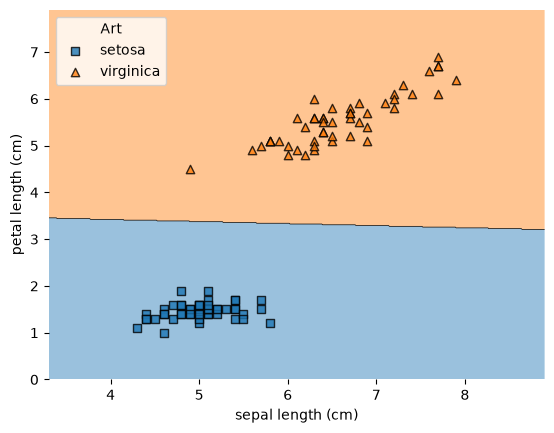

In [48]:
# Damit plot_decision_regions das Netz verwenden kann, braucht es ein Objekt mit einer Methode predict
class NetClassifier:
    def predict(self, X):
        with torch.no_grad():
            scores = model(torch.from_numpy(scale(X))) # Skaliere die Daten wie im Training
        return scores.argmax(dim=1).numpy() # Klasse mit dem höchsten Score

net_res = NetClassifier()

# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten (nur zwei Arten)
plot_regions(net_res, X_2, y_2, class_names = ['setosa', 'virginica'])

Die Achsen sind dieselben wie in den Grafiken der anderen Modelle. Eine gerade Linie trennt die beiden Arten, und alle 100 Blüten liegen auf der richtigen Seite.

### Schritt 2: Drei Klassen, drei Output-Knoten

Jetzt nehmen wir *versicolor* wieder dazu. Dafür ändern sich nur zwei Dinge: Wir verwenden die vollständigen Daten `X` und `y` (mit den Labels 0, 1 und 2), und das Netz bekommt einen dritten Output-Knoten. Das Modell, die Loss-Funktion, der Lern-Algorithmus und `NetClassifier` bleiben unverändert, denn sie verwenden immer die aktuellen Parameter `W` und `b`.

In [49]:
# Spezifiziere die Anzahl der Output-Knoten neu
output_dim = 3 # ein Knoten pro Klasse: setosa, versicolor, virginica

# Verwende die vollständigen Daten
X_t = torch.from_numpy(scale(X))
y_t = torch.from_numpy(y) # Klassen als ganze Zahlen 0, 1, 2

# Setze die Parameter mit neuen Startwerten auf
torch.manual_seed(0)
W = torch.rand(input_dim, output_dim, requires_grad = True)
b = torch.zeros(output_dim, requires_grad = True)

`W` hat jetzt 3 Spalten, also 6 Gewichte, und `b` 3 Konstanten. Wir starten das Training von vorne, denn die Parameter aus Schritt 1 passen nicht zur neuen Form.

In [50]:
# Training
for step in range(500):
    loss = training_step(X_t, y_t)
    if step % 50 == 0 or step == 499: # Zeige nur jeden 50. Schritt an
        print(f"Loss nach Schritt {step}: {loss:.4f}")

Loss nach Schritt 0: 1.0745
Loss nach Schritt 50: 0.6853
Loss nach Schritt 100: 0.5642
Loss nach Schritt 150: 0.5014
Loss nach Schritt 200: 0.4604
Loss nach Schritt 250: 0.4302
Loss nach Schritt 300: 0.4064
Loss nach Schritt 350: 0.3867
Loss nach Schritt 400: 0.3701
Loss nach Schritt 450: 0.3556


Loss nach Schritt 499: 0.3431


Mit drei Klassen beginnt der Loss bei 1,07, nahe an ln(3) ≈ 1,10, dem Loss eines Modells, das jeder Art die Wahrscheinlichkeit 1/3 gibt. Er sinkt langsamer als in Schritt 1, weil sich *versicolor* und *virginica* überlappen, und liegt nach 500 Schritten bei 0,34. Mit mehr Trainingsschritten würde der Loss weiter sinken.

In [51]:
# Berechne die Wahrscheinlichkeiten für alle Blüten
with torch.no_grad():
    probabilities = torch.softmax(model(X_t), dim=1)

# Zeige die Wahrscheinlichkeiten für die erste Blüte jeder Art (Zeilen 0, 50 und 100)
probabilities[[0, 50, 100]]

tensor([[0.9142, 0.0844, 0.0014],
        [0.0238, 0.5235, 0.4526],
        [0.0010, 0.1937, 0.8053]])

Jetzt enthält jede Zeile drei Wahrscheinlichkeiten, für *setosa*, *versicolor* und *virginica*. Die erste *setosa* erhält 91 % für *setosa*, die erste *virginica* 81 % für *virginica*. Bei der ersten *versicolor* ist das Modell unsicher: 52 % für *versicolor*, aber auch 45 % für *virginica*. Das passt zur Grafik am Anfang, in der sich diese beiden Arten überlappen.

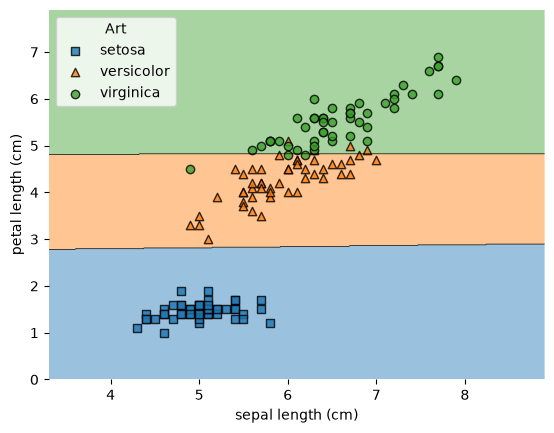

In [52]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
plot_regions(net_res, X, y)

Wie bei der logistischen Regression sind die Grenzen zwischen den Klassen gerade Linien. Das ist kein Zufall: Ein Netz ohne versteckte Schicht, dessen Scores mit Softmax in Wahrscheinlichkeiten umgewandelt werden, hat genau die Form einer (multinomialen) logistischen Regression. Bei ausreichend langem Training strebt unser Netz dieselben Parameter an wie eine logistische Regression ohne Regularisierung. `LogisticRegression` in scikit-learn bestraft dagegen standardmäßig große Gewichte (L2-Regularisierung), deshalb unterscheiden sich die Grenzen leicht. Außerdem ist unser Training nach 500 Schritten noch nicht abgeschlossen.

In [53]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
cm = metrics.confusion_matrix(y, net_res.predict(X))
cm

array([[50,  0,  0],
       [ 0, 46,  4],
       [ 0,  3, 47]])

143 von 150 Blüten werden richtig klassifiziert. Alle *setosa*-Blüten werden erkannt, vier *versicolor*-Blüten werden als *virginica* und drei *virginica*-Blüten als *versicolor* vorhergesagt. Das ist fast dasselbe Ergebnis wie bei der logistischen Regression (144 von 150). Ganz gleich sind die beiden Modelle nicht, wegen der Regularisierung in scikit-learn und weil unser Training nach 500 Schritten noch nicht abgeschlossen ist. Geschwungene Grenzen wie bei der SVM wären erst mit einer versteckten Schicht und einer nichtlinearen Aktivierungsfunktion möglich.

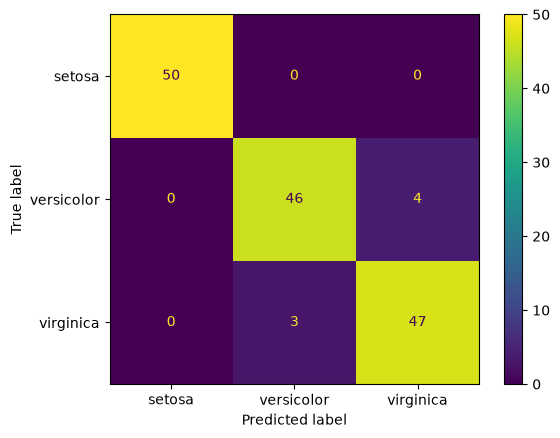

In [54]:
# Stelle die Konfusionsmatrix grafisch dar (das Semikolon unterdrückt die Textausgabe des Grafik-Objekts)
metrics.ConfusionMatrixDisplay(cm, display_labels = iris.target_names).plot();

## Quellen

* Han, J., Pei, J. und Tong, H. (2023): Data Mining: Concepts and Techniques. 4. Auflage. Morgan Kaufmann.
* Kelleher, J. D., Mac Namee, B. und D'Arcy, A. (2020): Fundamentals of Machine Learning for Predictive Data Analytics: Algorithms, Worked Examples, and Case Studies. 2. Auflage. MIT Press.
* https://scikit-learn.org/1.5/auto_examples/datasets/plot_iris_dataset.html
* https://scikit-learn.org/1.5/modules/tree.html
* https://rasbt.github.io/mlxtend/
* https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html